In [1]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u

t_now = Time.now().mjd

In [85]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False
    quality &= alert.properties['lsst_diaSource_scienceFlux'] >= 0
    quality &= alert.properties['lsst_diaSource_templateFlux'] >= 0

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
        pos_or_neg = -1
    else:
        diff_mag = -2.5* np.log10(10.**(0.4*(temp_mag - diff_img_mag)) + 1)
        pos_or_neg = 1

    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 0.1
    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts, latest_mjd):
    oid = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}

    #snr check
    if alerts[-1].properties['ant_survey'] == 4:
        if alerts[-1].properties['lsst_diaSource_snr'] < 8:
            return 'snr too low'
        elif lsst_quality(alerts[-1]) == False:
            return 'lsst alert quality fail'
        else:  # check if bright
            trig_alert = lsst_alert(alerts[-1])
            band = [*trig_alert][0]
            if trig_alert[band][1] > 21:
                return 'triggered alert too dim'
    elif alerts[-1].properties['ant_survey'] == 1:
        if (1.0857/alerts[-1].properties['ztf_sigmapsf']) < 8:
            return 'snr too low'

    for alert in alerts:
        #check mjd
        if alert.properties['ant_mjd'] < (math.floor(latest_mjd) - 30):
            continue

        # quality check
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert(alert)
            else:
                continue
        else:
            continue
            
        band = [*comp][0]
        #put quality data together organized by band
        if isinstance(oid[band], pd.DataFrame) == 0:
            oid_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            oid[band] = oid_df
            continue
        else:
            data_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            current_data = oid[band]
            oid[band] = pd.concat([current_data, data_df]).drop_duplicates().reset_index(drop=True)

    #checking if any data passed
    fail = 0
    for band in oid:
        if isinstance(oid[band], pd.DataFrame) == False:
            fail += 1
    if fail == 9:
        return 'no recent data'
    else:
        return oid

def var_params(oid):
    vp = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    data_lim = 0
    for band in oid:
        if band == 'locus':
            continue
        if isinstance(oid[band], pd.DataFrame) == 0:
            data_lim += 1
            continue
        if len(oid[band]) < 3:
            data_lim += 1
            vp[band] = {'diff_mag':0, 'var':0, 'hyper_v':0, 'data':oid[band]}
        
        max_mjd_i = oid[band].mjd.idxmax()
        diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
        var = np.var(oid[band]['oid_mag'])
        hv = float(np.sqrt(diff_mag ** 2 + (4 * var) ** 2))
        vp[band] = {'diff_mag':diff_mag, 'var':var, 'hyper_v':hv, 'data':oid[band]}
        
    if data_lim == 9:
        return 0
    else:
        return vp

def catalog_check(oid):
    oid['flags'] = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in oid['locus'].catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            oid['flags']['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            oid['flags']['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            oid['flags']['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(oid['locus'].catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and oid['locus'].catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                oid['flags']['gaia_likely_star'] = True
            if isinstance(oid['locus'].catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (oid['locus'].catalog_objects[cat][0]['parallax'] + 0.017)/oid['locus'].catalog_objects[cat][0]['parallax_error']
                alpha = oid['locus'].catalog_objects[cat][0]['pmra']/oid['locus'].catalog_objects[cat][0]['pmra_error']
                beta = oid['locus'].catalog_objects[cat][0]['pmdec']/oid['locus'].catalog_objects[cat][0]['pmdec_error']
                gamma = oid['locus'].catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    oid['flags']['gaia_astro_star'] = True
        alert_temp = oid['locus'].alerts[-1].properties
        if alert_temp['ant_survey'] == 1 and ((alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1)):
            oid['flags']['ps1_pointlike'] = True
    return oid

def query_by_chunk(mjd_start, mjd_end, ra_min=RA_MIN, ra_max=RA_MAX, dec_min=DEC_MIN, dec_max=DEC_MAX,
                     faint_lim=FAINT_MAG_LIM, bright_lim=BRIGHT_MAG_LIM, MIN_NDET=MIN_NDET, max_results=ANTARES_MAX_RETURN,
                     retries=3, wait=15):
    # set the query to fetch loci with alerts matching search criteria
    query = {
        “query”: {
            “bool”: {
                “filter”: [
                    {“range”: {“properties.newest_alert_observation_time”: {“gte”: mjd_start, “lte”: mjd_end}}}, # locus was active after mjd_start
                    {“range”: {“properties.newest_alert_magnitude”: {“lte”: faint_lim}}},  # latest mag is brighter than faint mag limit
                    {“range”: {“properties.num_alerts”: {“gte”: MIN_NDET}}},
                    {“range”: {“ra”:  {“gte”: ra_min,  “lte”: ra_max}}},
                    {“range”: {“dec”: {“gte”: dec_min, “lte”: dec_max}}},
                ]
            }
        }
    }

    # sometimes the ANTARES server times out so try a few times
    # before giving up and returning an empty list (to avoid crashing the entire query)
    for attempt in range(retries):
        try:
            loci = list(search(query))
            if len(loci) >= max_results:
                warnings.warn(
                    f”Chunk MJD {mjd_start:.1f}–{mjd_end:.1f} hit the {max_results}-result max.”
                    f”— Reduce QUERY_DT or this window is incomplete.“,
                    stacklevel=2
                )
            return loci
        except Exception as e:
            if attempt < retries - 1:
                print(f”  Chunk {mjd_start}–{mjd_end} failed (attempt {attempt+1}/{retries}): {e}.“)
                time.sleep(wait)
            else:
                print(f”  Chunk {mjd_start}–{mjd_end} giving up after {retries} attempts.“)
                return []

In [86]:
mag_max = 21
# mag_min = 17

q_lsst_magcut = {
    "query": {
        "bool": {
            "filter": [
                { "range": { "properties.newest_alert_magnitude": { "lte": mag_max} } },
                { "exists": { "field": "properties.survey.lsst" } },
                { "range": { "properties.newest_alert_observation_time": { "gte": 61234} } },
                { "range": { "properties.newest_alert_observation_time": { "lte": 61235} } },
                {"term": { "tags": "lsst_scimma_quality_transient"} }
                  ]
        }
    }
}

oids_sample = {}
# counting how many were checked and for those that failed, why they failed
checked = 0
snr_fail = 0 # triggering lsst alert too low
recent_fail = 0 # no recent data
lsst_q_f = 0 # triggering lsst alert is not quality
vp_dl_f = 0 # param calc is data limited on all bands
mag_f = 0 # triggered alert too dim

for locus in search.search(q_lsst_magcut):

    oid_dv = locus.to_devkit()
    oid_locus = DevKitLocus.model_validate(oid_dv)

    oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])

    if isinstance(oid_here, str):
        if oid_here == 'snr too low':
            snr_fail += 1
        elif oid_here == 'no recent data':
            recent_fail += 1
        elif oid_here == 'lsst alert quality fail':
            lsst_q_f += 1
        elif oid_here == 'triggered alert too dim':
            mag_f += 1
    else:
        vp_here = var_params(oid_here)
        if isinstance(vp_here, dict) == 0:
            vp_dl_f += 1
        else:
            oids_sample[oid_dv['id']] = vp_here
            oids_sample[oid_dv['id']]['locus'] = locus
            
    checked += 1
    # if len(oids_sample) >= 8000:
    # if checked > 100:
    #     break

KeyboardInterrupt: 

In [43]:
print(f'total: {checked}, passed: {len(oids_sample)}\nfails from: snr {snr_fail}, recency {recent_fail}, brightness {mag_f}, quality {lsst_q_f}, data limitting {vp_dl_f}')

total: 10000, passed: 169
fails from: snr 823, recency 2, brightness 365, quality 1104, data limitting 7528


In [5]:
oids_sample

{'ANT2026sv5wtz11jr73': {'lsst_g': 0,
  'lsst_r': {'diff_mag': 0.3540765190740487,
   'var': 0.11047799971135736,
   'hyper_v': 0.5662653053853449,
   'data':             mjd    oid_mag  template_mag  diff_mag  pos/neg
   0  61228.193743  19.291893     19.016777 -0.275116       -1
   1  61228.194242  19.320917     19.043033 -0.277884       -1
   2  61234.289908  18.601764     18.955840  0.354077        1},
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g': 0,
  'ztf_R': 0,
  'ztf_i': 0,
  'locus': <antares_client.models.Locus at 0x30630a4e0>},
 'ANT2026huxxdre937ru': {'lsst_g': 0,
  'lsst_r': {'diff_mag': -6.082816509767834,
   'var': 5.51414773370468,
   'hyper_v': 22.87998820710866,
   'data':             mjd    oid_mag  template_mag  diff_mag  pos/neg
   0  61228.193743  23.224550     20.573083 -2.651467       -1
   1  61232.265425  20.956849     20.000759 -0.956091       -1
   2  61234.289908  26.668561     20.585745 -6.082817       -1},
  'lsst_i': 0,
  'lsst_z

In [92]:
vp_f = 0 #variability parameters fail
hv_oids = {}
dm = []
var = []
hv = []
for oid in oids_sample:
    band_f = 0
    dm_temp = []
    var_temp = []
    hv_temp = []
    oids_sample[oid] = catalog_check(oids_sample[oid])
    for band in oids_sample[oid]:
        if oids_sample[oid][band] == 'locus' or band == 'flags':
            continue
        elif isinstance(oids_sample[oid][band], dict) == 0:
            band_f += 1
            continue
        dm_temp.append(oids_sample[oid][band]['diff_mag'])
        var_temp.append(oids_sample[oid][band]['var'])
        hv_temp.append(oids_sample[oid][band]['hyper_v'])
    if max(hv_temp) >= 1:
            hv_oids[oid] = oids_sample[oid]
    dm.append(max(dm_temp))
    var.append(max(var_temp))
    hv.append(max(hv_temp))

In [69]:
len(hv_oids)

8

[]

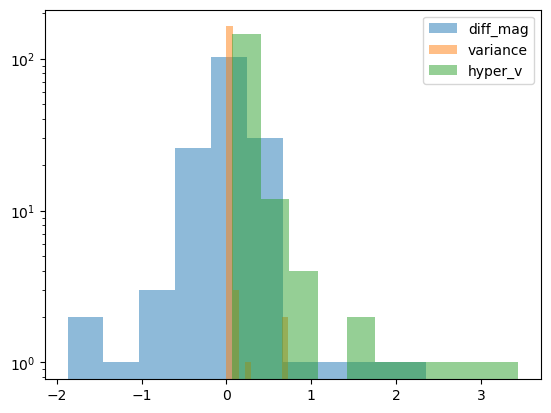

In [66]:
plt.hist(dm, alpha = 0.5, label = 'diff_mag')
plt.hist(var, alpha = 0.5, label = 'variance')
plt.hist(hv, alpha = 0.5, label = 'hyper_v')
plt.legend()
plt.semilogy()

In [93]:
mag_max = 21

q_lsst_magcut = {
    "query": {
        "bool": {
            "filter": [
                { "range": { "properties.newest_alert_magnitude": { "lte": mag_max} } },
                { "exists": { "field": "properties.survey.lsst" } },
                { "range": { "properties.newest_alert_observation_time": { "gte": 61233} } },
                { "range": { "properties.newest_alert_observation_time": { "lte": 61234} } },
                {"term": { "tags": "lsst_scimma_quality_transient"} }
                  ]
        }
    }
}

oids61233_sample = {}
# counting how many were checked and for those that failed, why they failed
checked = 0
snr_fail = 0 # triggering lsst alert too low
recent_fail = 0 # no recent data
lsst_q_f = 0 # triggering lsst alert is not quality
vp_dl_f = 0 # param calc is data limited on all bands
mag_f = 0 # triggered alert too dim

for locus in search.search(q_lsst_magcut):

    oid_dv = locus.to_devkit()
    oid_locus = DevKitLocus.model_validate(oid_dv)

    oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])

    if isinstance(oid_here, str):
        if oid_here == 'snr too low':
            snr_fail += 1
        elif oid_here == 'no recent data':
            recent_fail += 1
        elif oid_here == 'lsst alert quality fail':
            lsst_q_f += 1
        elif oid_here == 'triggered alert too dim':
            mag_f += 1
    else:
        vp_here = var_params(oid_here)
        if isinstance(vp_here, dict) == 0:
            vp_dl_f += 1
        else:
            oids61233_sample[oid_dv['id']] = vp_here
            oids61233_sample[oid_dv['id']]['locus'] = locus
            
    checked += 1
    # if len(oids_sample) >= 8000:
    # if checked > 100:
    #     break

In [94]:
print(f'total: {checked}, passed: {len(oids61233_sample)}\nfails from: snr {snr_fail}, recency {recent_fail}, brightness {mag_f}, quality {lsst_q_f}, data limitting {vp_dl_f}')

total: 633, passed: 77
fails from: snr 60, recency 0, brightness 152, quality 267, data limitting 75


In [115]:
t_now

np.float64(61270.83769126335)

im gonna try the same as above, but instead of filtering for the last time lsst was active im gonna just use last nights data. this will test for occasions like now when lsst is down to see if we still get a good sample of hv oids. lsst has been out for over a month, so all data used in this should come from ztf

In [116]:
mag_max = 21

q_lsst_magcut = {
    "query": {
        "bool": {
            "filter": [
                { "range": { "properties.newest_alert_magnitude": { "lte": mag_max} } },
                { "exists": { "field": "properties.survey.lsst" } },
                { "range": { "properties.newest_alert_observation_time": { "gte": t_now - 1} } },
                {"term": { "tags": "lsst_scimma_quality_transient"} }
                  ]
        }
    }
}

oids61270_sample = {}
# counting how many were checked and for those that failed, why they failed
checked_61270 = 0
snr_fail_61270 = 0 # triggering lsst alert too low
recent_fail_61270 = 0 # no recent data
lsst_q_f_61270 = 0 # triggering lsst alert is not quality
vp_dl_f_61270 = 0 # param calc is data limited on all bands
mag_f_61270 = 0 # triggered alert too dim

for locus in search.search(q_lsst_magcut):

    oid_dv = locus.to_devkit()
    oid_locus = DevKitLocus.model_validate(oid_dv)

    oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])

    if isinstance(oid_here, str):
        if oid_here == 'snr too low':
            snr_fail_61270 += 1
        elif oid_here == 'no recent data':
            recent_fail_61270 += 1
        elif oid_here == 'lsst alert quality fail':
            lsst_q_f_61270 += 1
        elif oid_here == 'triggered alert too dim':
            mag_f_61270 += 1
    else:
        vp_here = var_params(oid_here)
        if isinstance(vp_here, dict) == 0:
            vp_dl_f_61270 += 1
        else:
            oids61270_sample[oid_dv['id']] = vp_here
            oids61270_sample[oid_dv['id']]['locus'] = locus
            
    checked_61270 += 1
    # if len(oids_sample) >= 8000:
    # if checked > 100:

    #     break

/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_1961/3644121852.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))
/var/folders/ym/gbj1z46s0wg5zdmkkq0xpptr0000gs/T/ipykernel_1961/3644121852.py:48: RuntimeWarning: invalid value encountered in log10
  diff_mag = -2.5* np.log10(1 - 10.**(0.4*(temp_mag - diff_img_mag)))


In [117]:

print(f'total: {checked_61270}, passed: {len(oids61270_sample)}\nfails from: snr {snr_fail_61270}, recency {recent_fail_61270}, brightness {mag_f_61270}, quality {lsst_q_f_61270}, data limitting {vp_dl_f_61270}')


total: 2595, passed: 900
fails from: snr 1407, recency 53, brightness 0, quality 0, data limitting 205


159


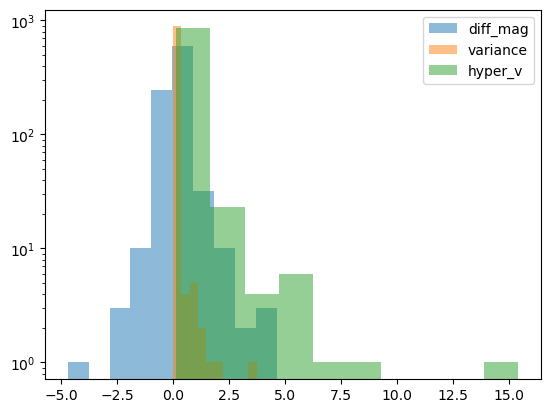

In [122]:
vp_f_61270 = 0 #variability parameters fail
hv_oids_61270 = {}
dm = []
var = []
hv = []
for oid in oids61270_sample:
    band_f = 0
    dm_temp = []
    var_temp = []
    hv_temp = []
    oids61270_sample[oid] = catalog_check(oids61270_sample[oid])
    for band in oids61270_sample[oid]:
        if oids61270_sample[oid][band] == 'locus' or band == 'flags':
            continue
        elif isinstance(oids61270_sample[oid][band], dict) == 0:
            band_f += 1
            continue
        dm_temp.append(oids61270_sample[oid][band]['diff_mag'])
        var_temp.append(oids61270_sample[oid][band]['var'])
        hv_temp.append(oids61270_sample[oid][band]['hyper_v'])
    if max(hv_temp) >= 1:
            hv_oids_61270[oid] = oids61270_sample[oid]
    dm.append(max(dm_temp))
    var.append(max(var_temp))
    hv.append(max(hv_temp))

plt.hist(dm, alpha = 0.5, label = 'diff_mag')
plt.hist(var, alpha = 0.5, label = 'variance')
plt.hist(hv, alpha = 0.5, label = 'hyper_v')
plt.legend()
plt.semilogy()
print(len(hv_oids_61270))

this is really interesting, this sample has so much more variance than the previous sampels from 61234 and 61233 (which ended up being limited to lsst data). i wonder what this distribution will look like once lsst is up again and itd be easier to find oids observe by both lsst and ztf in my querying. with a hv thresh of 1, ~17% of the oids passed

# testing filter params using known object types
## tdes
testing above work using [Yao et al.](https://ui.adsabs.harvard.edu/abs/2023ApJ...955L...6Y/abstract) TDE list

In [60]:
tde_ids = ['ZTF18acaqdaa', 'ZTF18acnbpmd', 'ZTF19aabbnzo', 'ZTF19aaciohh', 'ZTF17aaazdba', 'ZTF19aakswrb', 'ZTF19aaniqrr', 
        'ZTF19aapreis', 'ZTF19aarioci', 'ZTF19abzrhgq', 'ZTF19acspeuw', 'ZTF20aabqihu', 'ZTF20abfcszi', 'ZTF20abgwfek',
        'ZTF20abnorit', 'ZTF20acaazkt', 'ZTF20achpcvt', 'ZTF20acitpfz', 'ZTF20acnznms', 'ZTF20acvezvs', 'ZTF20acwytxn', 
        'ZTF21aaaokyp', 'ZTF21aakfqwq', 'ZTF21aanxhjv', 'ZTF21aauuybx', 'ZTF21abaxaqq', 'ZTF21abcgnqn', 'ZTF21abhrchb',
        'ZTF21abjrysr', 'ZTF21abqhkjd', 'ZTF21abqtckk', 'ZTF21abxngcz', 'ZTF21acafvhf', 'ZTF18abavruc', 'ZTF20aaivego', 
       'ZTF20ackdkva', 'ZTF21abcmepi', 'ZTF21abwjibi', 'ZTF20aaurjbj', 'ZTF20aayxdse', 'ZTF20achuhlt', 'ZTF21aaglrzc', 
       'ZTF21abdmevk', 'ZTF21abzciqh', 'ZTF19abulzhy', 'ZTF20abgoocl', 'ZTF19acfwynw', 'ZTF20abobpcb', 'ZTF21aavdqgf', 
       'ZTF20aasuiks ', 'ZTF20acbcfaa', 'ZTF19abvgxrq', 'ZTF21abislwc', 'ZTF20aczhaeu', 'ZTF19aaywayr']

tde_sample = {}
tde_snr_fail = 0 # triggering lsst alert too low
tde_recent_fail = 0 # no recent data
tde_lsst_q_f = 0 # triggering lsst alert is not quality
tde_vp_dl_f = 0 # param calc is data limited on all bands
tde_mag_f = 0 # triggered alert too dim
for ztf_id in tde_ids:
    locus = search.get_by_ztf_object_id(ztf_id)
    if locus == None:
        continue
        
    oid_dv = locus.to_devkit()
    oid_locus = DevKitLocus.model_validate(oid_dv)
    oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])

    if isinstance(oid_here, str):
        if oid_here == 'snr too low':
            tde_snr_fail += 1
        elif oid_here == 'no recent data':
            tde_recent_fail += 1
        elif oid_here == 'lsst alert quality fail':
            tde_lsst_q_f += 1
        elif oid_here == 'triggered alert too dim':
            tde_mag_f += 1
    else:
        
        vp_here = var_params(oid_here)
        if isinstance(vp_here, dict) == 0:
            tde_vp_dl_f += 1
        else:
            tde_sample[oid_locus.id+' '+ztf_id] = vp_here
            tde_sample[oid_locus.id+' '+ztf_id]['locus'] = locus

In [61]:
print(f'total: {len(tde_ids)}, passed: {len(tde_sample)}\nfails from: snr {tde_snr_fail}, recency {tde_recent_fail}, brightness {tde_mag_f}, quality {tde_lsst_q_f}, data limitting {tde_vp_dl_f}')

total: 55, passed: 4
fails from: snr 48, recency 0, brightness 0, quality 0, data limitting 2


In [62]:
tde_sample

{'ANT2020atxp6 ZTF20abgwfek': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g': {'diff_mag': -0.9763729434152528,
   'var': 0.0030296481971546197,
   'hyper_v': 0.9764481475862099,
   'data':             mjd    oid_mag  template_mag  diff_mag  pos/neg
   0  59040.231725  17.596543     18.683001 -1.086457        1
   1  59043.190937  17.706628     18.683001 -0.976373        1},
  'ztf_R': {'diff_mag': -0.36923235142600186,
   'var': 0.01963413517675131,
   'hyper_v': 0.3774924072955609,
   'data':             mjd    oid_mag  template_mag  diff_mag  pos/neg
   0  59037.189387  17.300311     18.085001 -0.784690        1
   1  59040.197107  17.370729     18.085001 -0.714272        1
   2  59046.189549  17.473482     18.085001 -0.611519        1
   3  59049.184861  17.514475     18.085001 -0.570526        1
   4  59063.168495  17.617302     18.085001 -0.467699        1
   5  59065.168206  17.715769     18.085001 -0.369232        1},
  'ztf_i

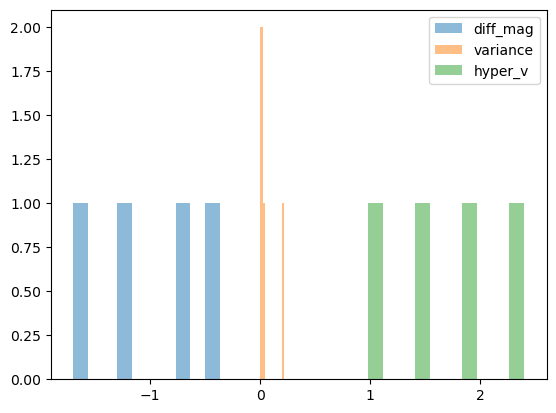

In [64]:
vp_f = 0 #variability parameters fail
# hv_oids = {}
tde_dm = []
tde_var = []
tde_hv = []
for oid in tde_sample:
    dm_temp = []
    var_temp = []
    hv_temp = []
    band_f = 0
    for band in tde_sample[oid]:
        if tde_sample[oid][band] == 'locus':
            continue
        elif isinstance(tde_sample[oid][band], dict) == 0:
            band_f += 1
            continue

        dm_temp.append(tde_sample[oid][band]['diff_mag'])
        var_temp.append(tde_sample[oid][band]['var'])
        hv_temp.append(tde_sample[oid][band]['hyper_v'])
        # if oids_sample[oid][band]['hyper_v'] >= 1:
        #     hv_oids[oid] = oids_sample[oid]
    tde_dm.append(max(dm_temp))
    tde_var.append(max(var_temp))
    tde_hv.append(max(hv_temp))

plt.hist(tde_dm, alpha = 0.5, label = 'diff_mag')
plt.hist(tde_var, alpha = 0.5, label = 'variance')
plt.hist(tde_hv, alpha = 0.5, label = 'hyper_v')
plt.legend()

## clagns/evqs
testing above work with CLAGN/EVQ sample from [Zeltyn et al](https://ui.adsabs.harvard.edu/abs/2024ApJ...966...85Z/abstract)

In [113]:
clagn_checked = 0
clagn_snr_fail = 0 # triggering lsst alert too low
clagn_recent_fail = 0 # no recent data
clagn_lsst_q_f = 0 # triggering lsst alert is not quality
clagn_vp_dl_f = 0 # param calc is data limited on all bands
clagn_mag_f = 0 # triggered alert too dim
clagn_found = 0

clagn_info = pd.read_csv('clagn_evq_sample.csv')
clagn_sample = {}
for (ra, dec) in zip(clagn_info['RA'], clagn_info['Dec']):
    center = SkyCoord(ra, dec, unit='deg')
    angle = Angle('1s')

    for locus in search.cone_search(center, angle):
        oid_dv = locus.to_devkit()
        known_agn = False
        # check if known agn (as these all are)
        for cat in locus.catalog_objects:
            if cat == 'veron_agn_qso' or cat == 'milliquas':
                known_agn = True
        if known_agn == False:
            continue
        clagn_found += 1
            
        oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(oid_dv)
        
    
        oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])
    
        if isinstance(oid_here, str):
            if oid_here == 'snr too low':
                clagn_snr_fail += 1
            elif oid_here == 'no recent data':
                clagn_recent_fail += 1
            elif oid_here == 'lsst alert quality fail':
                clagn_lsst_q_f += 1
            elif oid_here == 'triggered alert too dim':
                clagn_mag_f += 1
        else:
            vp_here = var_params(oid_here)
            if isinstance(vp_here, dict) == 0:
                clagn_vp_dl_f += 1
            else:
                clagn_sample[oid_dv['id']] = vp_here
                clagn_sample[oid_dv['id']]['locus'] = locus
    clagn_checked += 1


In [114]:
print(f'total: {clagn_checked}, found: {clagn_found}, passed: {len(clagn_sample)}\nfails from: snr {clagn_snr_fail}, recency {clagn_recent_fail}, brightness {clagn_mag_f}, quality {clagn_lsst_q_f}, data limitting {clagn_vp_dl_f}')


total: 208, found: 75, passed: 8
fails from: snr 63, recency 0, brightness 0, quality 1, data limitting 3


In [110]:
clagn_sample

{'ANT2020epqzg': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g': {'diff_mag': 0.853541637483973,
   'var': 0.007778087422580697,
   'hyper_v': 0.8541084856281871,
   'data':              mjd    oid_mag  template_mag  diff_mag  pos/neg
   0   61243.443472  19.100040     18.149000  0.951040       -1
   1   61244.440069  19.164412     18.165001  0.999411       -1
   2   61246.379826  19.017411     18.149000  0.868411       -1
   3   61246.462095  19.179140     18.165001  1.014139       -1
   4   61248.458252  19.239183     18.165001  1.074182       -1
   5   61248.458727  19.004558     18.149000  0.855558       -1
   6   61251.435880  18.903312     18.149000  0.754312       -1
   7   61260.379630  19.235442     18.165001  1.070441       -1
   8   61260.380104  19.009165     18.149000  0.860165       -1
   9   61262.477268  19.074023     18.149000  0.925023       -1
   10  61262.477743  19.108163     18.165001  0.943163       -1
   11  61

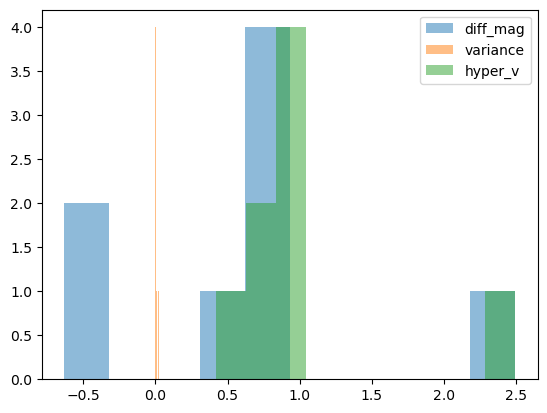

In [112]:
vp_f = 0 #variability parameters fail
# hv_oids = {}
clagn_dm = []
clagn_var = []
clagn_hv = []
for oid in clagn_sample:
    dm_temp = []
    var_temp = []
    hv_temp = []
    band_f = 0
    for band in clagn_sample[oid]:
        if clagn_sample[oid][band] == 'locus':
            continue
        elif isinstance(clagn_sample[oid][band], dict) == 0:
            band_f += 1
            continue

        dm_temp.append(clagn_sample[oid][band]['diff_mag'])
        var_temp.append(clagn_sample[oid][band]['var'])
        hv_temp.append(clagn_sample[oid][band]['hyper_v'])
        # if oids_sample[oid][band]['hyper_v'] >= 1:
        #     hv_oids[oid] = oids_sample[oid]
    clagn_dm.append(max(dm_temp))
    clagn_var.append(max(var_temp))
    clagn_hv.append(max(hv_temp))

plt.hist(clagn_dm, alpha = 0.5, label = 'diff_mag')
plt.hist(clagn_var, alpha = 0.5, label = 'variance')
plt.hist(clagn_hv, alpha = 0.5, label = 'hyper_v')
plt.legend()

In [123]:
a = search.get_by_id('ANT2026huxxdre937ru')

In [126]:
info = lsst_alert(a.alerts[-1])
info

{'lsst_r': [61234.28990837613,
  26.668561244840962,
  20.585744735073128,
  -6.082816509767834,
  -1]}

In [127]:
a.locus_id

'ANT2026huxxdre937ru'